In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import hdbscan

sns.set_theme(style="whitegrid")
print("Pustaka klasterisasi hierarki (SciPy, Scikit-Learn, HDBSCAN) berhasil dimuat.")

Pustaka klasterisasi hierarki (SciPy, Scikit-Learn, HDBSCAN) berhasil dimuat.


In [2]:
# Memuat data cafe yang telah dipreprocessing
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes):
    path_cafes = '../dataset/cafes.csv'

df_cafes = pd.read_csv(path_cafes)
if 'price_min_imputed' not in df_cafes.columns:
    df_cafes['price_min_imputed'] = df_cafes['price_min'].fillna(df_cafes['price_min'].median())
    df_cafes['price_max_imputed'] = df_cafes['price_max'].fillna(df_cafes['price_max'].median())

fitur_hierarki = ['latitude', 'longitude', 'rating', 'review_count', 'price_min_imputed', 'price_max_imputed']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cafes[fitur_hierarki])

print(f"Dataset cafe untuk klasterisasi hierarki: {X_scaled.shape}")

Dataset cafe untuk klasterisasi hierarki: (275, 6)


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



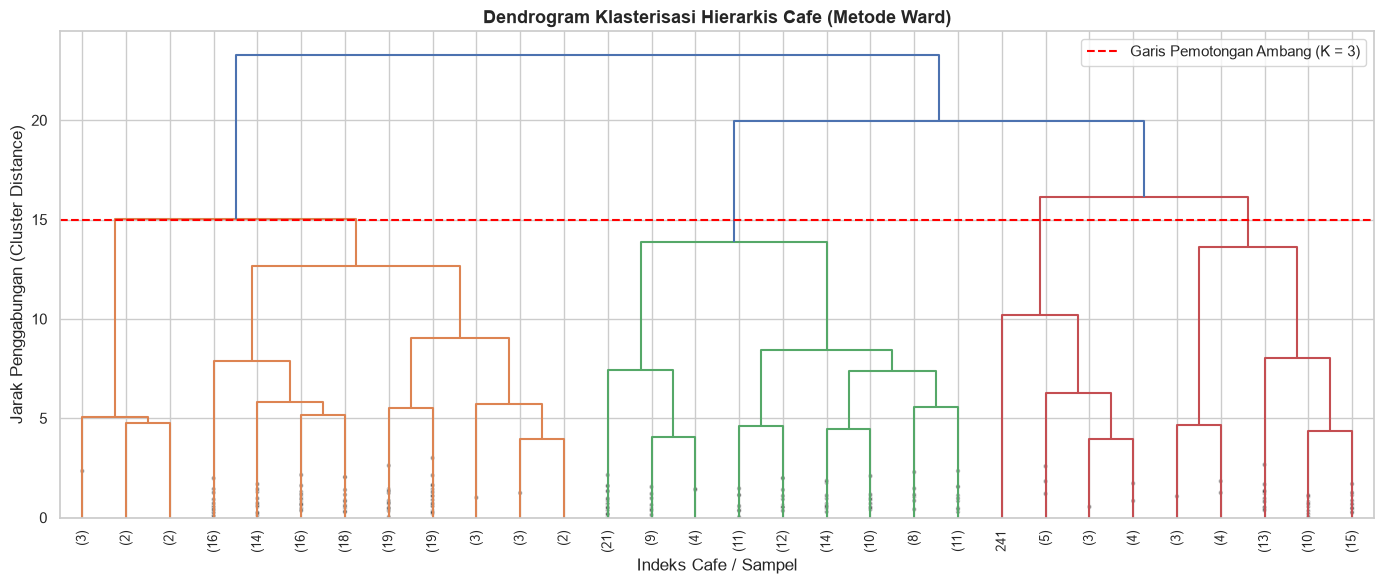

In [3]:
# Menghitung matriks linkage menggunakan metode Ward
Z_ward = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
plt.title('Dendrogram Klasterisasi Hierarkis Cafe (Metode Ward)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Cafe / Sampel')
plt.ylabel('Jarak Penggabungan (Cluster Distance)')

# Tampilkan dendrogram dengan pemotongan visual pada jarak 15
dendrogram(Z_ward, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=9., show_contracted=True)
plt.axhline(y=15, color='red', linestyle='--', label='Garis Pemotongan Ambang (K = 3)')
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Komparasi Silhouette Score untuk berbagai linkage pada K = 3
k_clusters = 3
linkage_methods = ['ward', 'complete', 'average']
sil_scores_linkage = {}

for method in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=k_clusters, linkage=method)
    labels = agg.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores_linkage[method] = score

df_linkage_comp = pd.DataFrame(list(sil_scores_linkage.items()), columns=['Metode_Linkage', 'Silhouette_Score'])
print("=== PERBANDINGAN SILHOUETTE SCORE METODE LINKAGE (K=3) ===")
print(df_linkage_comp.to_string(index=False))

# Tetapkan Ward sebagai linkage terbaik
agg_final = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
df_cafes['cluster_hierarki'] = agg_final.fit_predict(X_scaled)

=== PERBANDINGAN SILHOUETTE SCORE METODE LINKAGE (K=3) ===
Metode_Linkage  Silhouette_Score
          ward          0.209293
      complete          0.181587
       average          0.462294


In [5]:
# Melatih model HDBSCAN
clusterer_hdb = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5, metric='euclidean', gen_min_span_tree=True)
df_cafes['cluster_hdbscan'] = clusterer_hdb.fit_predict(X_scaled)

labels_hdb = df_cafes['cluster_hdbscan']
n_clusters_hdb = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise_hdb = (labels_hdb == -1).sum()

mask_valid_hdb = labels_hdb != -1
if n_clusters_hdb > 1 and mask_valid_hdb.sum() > n_clusters_hdb:
    sil_hdb = silhouette_score(X_scaled[mask_valid_hdb], labels_hdb[mask_valid_hdb])
else:
    sil_hdb = 0.0

print(f"Hasil Klasterisasi HDBSCAN:")
print(f"- Jumlah Klaster Ditemukan : {n_clusters_hdb}")
print(f"- Jumlah Noise              : {n_noise_hdb} ({n_noise_hdb/len(df_cafes)*100:.2f}%)")
print(f"- Silhouette Score (Non-Noise): {sil_hdb:.4f}")
print("\nSebaran Anggota Tiap Klaster HDBSCAN:")
print(labels_hdb.value_counts())

Hasil Klasterisasi HDBSCAN:
- Jumlah Klaster Ditemukan : 3
- Jumlah Noise              : 40 (14.55%)
- Silhouette Score (Non-Noise): 0.2665

Sebaran Anggota Tiap Klaster HDBSCAN:
cluster_hdbscan
 1    133
 0    102
-1     40
Name: count, dtype: int64


<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



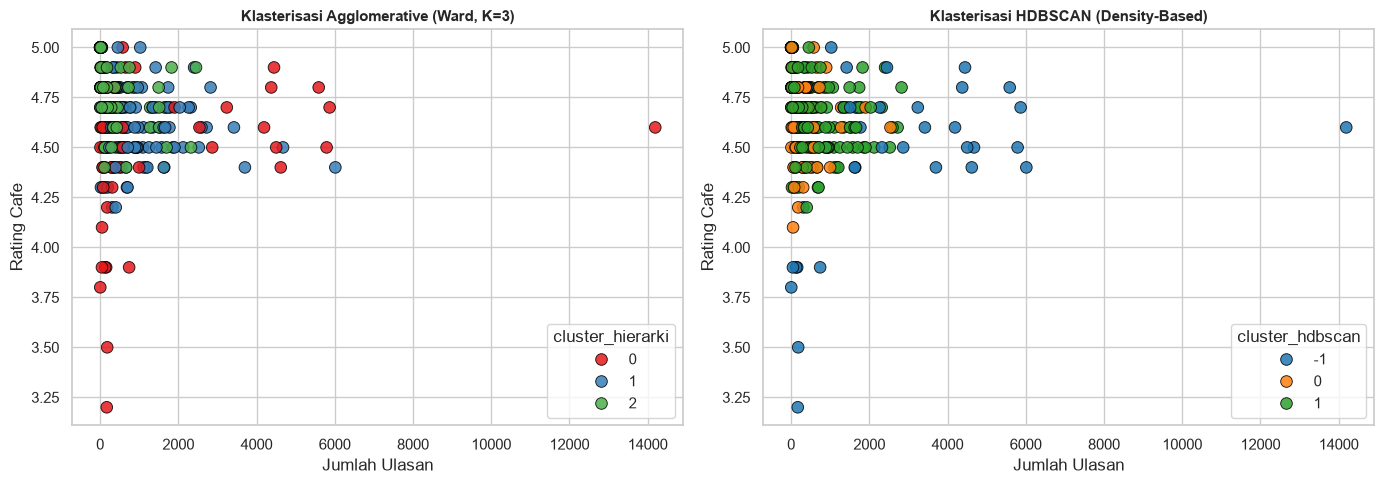

In [6]:
# Visualisasi scatter plot rating vs review_count berdasarkan klaster hierarkis
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_cafes, x='review_count', y='rating', hue='cluster_hierarki', palette='Set1', s=70, alpha=0.85, edgecolor='black')
plt.title(f'Klasterisasi Agglomerative (Ward, K={k_clusters})', fontsize=11, fontweight='bold')
plt.xlabel('Jumlah Ulasan')
plt.ylabel('Rating Cafe')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_cafes, x='review_count', y='rating', hue='cluster_hdbscan', palette='tab10', s=70, alpha=0.85, edgecolor='black')
plt.title(f'Klasterisasi HDBSCAN (Density-Based)', fontsize=11, fontweight='bold')
plt.xlabel('Jumlah Ulasan')
plt.ylabel('Rating Cafe')

plt.tight_layout()
plt.show()

In [7]:
# Menyimpan dataset cafe dengan label hierarkis
os.makedirs('../outputs', exist_ok=True)
path_out_hierarki = '../outputs/cafes_hierarchical_js5.csv'
df_cafes[['id', 'name', 'rating', 'review_count', 'cluster_hierarki', 'cluster_hdbscan']].to_csv(path_out_hierarki, index=False)
print(f"Hasil klasterisasi hierarkis tersimpan ke: {path_out_hierarki}")

Hasil klasterisasi hierarkis tersimpan ke: ../outputs/cafes_hierarchical_js5.csv
